In [82]:
import pandas as pd

In [83]:
clust_res = pd.read_csv('data/clust-results.tsv', sep='\t', header=None)
clust_res.columns = ['type', 'cluster_id', 'query_length', 'similarity', 'strand', 0, 1, 'align_res', 'query_label', 'centroid_label']
clust_res = clust_res[['type', 'cluster_id', 'query_length', 'similarity', 'strand', 'align_res', 'query_label']]

In [84]:
cluster = clust_res[(clust_res['type'] == 'S') | (clust_res['type'] == 'H')]
cluster.head(20)

,type,cluster_id,query_length,similarity,strand,align_res,query_label
0,S,0,977,*,*,*,FJ008022.1
1,H,0,977,100.0,+,=,FJ008023.1
2,H,0,977,100.0,+,=,FJ008024.1
3,H,0,977,100.0,+,=,FJ008025.1
4,S,1,801,*,*,*,L04457.1
5,S,2,780,*,*,*,NC_063789.1
6,S,3,777,*,*,*,MH142315.1
7,H,3,777,100.0,+,=,MH325167.1
8,S,4,777,*,*,*,MN883605.1
9,S,5,777,*,*,*,MN883607.1


In [85]:
cluster.value_counts(subset='cluster_id').sort_values(ascending=False)

cluster_id
525    70
611    54
250    50
684    42
74     35
       ..
886     1
871     1
458     1
834     1
460     1
Name: count, Length: 1527, dtype: int64

In [86]:
db = pd.read_csv('data/cox2-db-filtered.csv', sep='\t')
db

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,tax_id_sanitized,organism_name_sanitized
0,JF414536.1,12-DEC-2013,Pseudoperonospora celtidis isolate SMK17780 cy...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2162,Pseudoperonospora celtidis,291623,<0,726,1.0,291623,Pseudoperonospora celtidis
1,HM635956.1,12-DEC-2013,Pseudoperonospora cannabina isolate NY409 cyto...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATAAACTTTCATCATGATTT...,550,Pseudoperonospora cannabina,291622,<0,>550,1.0,291622,Pseudoperonospora cannabina
2,HM635955.1,12-DEC-2013,Pseudoperonospora cannabina isolate U181 cytoc...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATAAACTTTCATCATGATTT...,550,Pseudoperonospora cannabina,291622,<0,>550,1.0,291622,Pseudoperonospora cannabina
3,HM635953.1,12-DEC-2013,Pseudoperonospora urticae isolate PDD1 cytochr...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATTAACTTTCATCATGATTT...,550,Pseudoperonospora urticae,162119,<0,>550,1.0,162119,Pseudoperonospora urticae
4,HM635952.1,12-DEC-2013,Pseudoperonospora urticae isolate HOH1111 cyto...,"Runge,F., Choi,Y.-J. and Thines,M.",CGGCAACTCCCGTTATGGAAGGTATTATTAACTTTCATCATGATTT...,550,Pseudoperonospora urticae,162119,<0,>550,1.0,162119,Pseudoperonospora urticae
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3743,LC730894.1,31-AUG-2023,Aphanomyces iridis CK14D1 mitochondrial cox2 g...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces iridis,601994,<0,>552,1.0,601994,Aphanomyces iridis
3744,LC730893.1,31-AUG-2023,Aphanomyces iridis CK12DI1 mitochondrial cox2 ...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces iridis,601994,<0,>552,1.0,601994,Aphanomyces iridis
3745,LC730891.1,31-AUG-2023,Aphanomyces cochlioides MAFF 305845 mitochondr...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces cochlioides,112091,<0,>552,1.0,112091,Aphanomyces cochlioides
3746,LC730890.1,31-AUG-2023,Aphanomyces cladogamus NBRC 103816 mitochondri...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTATTTTTTTTTTTAG...,552,Aphanomyces cladogamus,253176,<0,>552,1.0,253176,Aphanomyces cladogamus


In [87]:
merged = db.merge(cluster, how='left', left_on='accession', right_on='query_label')
merged['trimed_seq_len'] = merged['sequence'].str.len()
merged

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,...,tax_id_sanitized,organism_name_sanitized,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,JF414536.1,12-DEC-2013,Pseudoperonospora celtidis isolate SMK17780 cy...,"Mitchell,M.N., Ocamb,C.M., Grunwald,N.J., Manc...",GAACCTTGGCAATTAGGTTTTCAAGATCCTGCAACTCCCGTTATGG...,2162,Pseudoperonospora celtidis,291623,<0,726,...,291623,Pseudoperonospora celtidis,S,76,726,*,*,*,JF414536.1,726
1,HM635956.1,12-DEC-2013,Pseudoperonospora cannabina isolate NY409 cyto...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATAAACTTTCATCATGATTT...,550,Pseudoperonospora cannabina,291622,<0,>550,...,291622,Pseudoperonospora cannabina,H,705,550,100.0,+,=,HM635956.1,550
2,HM635955.1,12-DEC-2013,Pseudoperonospora cannabina isolate U181 cytoc...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATAAACTTTCATCATGATTT...,550,Pseudoperonospora cannabina,291622,<0,>550,...,291622,Pseudoperonospora cannabina,H,705,550,100.0,+,=,HM635955.1,550
3,HM635953.1,12-DEC-2013,Pseudoperonospora urticae isolate PDD1 cytochr...,"Runge,F., Choi,Y.-J. and Thines,M.",CAGCAACTCCCGTTATGGAAGGTATTATTAACTTTCATCATGATTT...,550,Pseudoperonospora urticae,162119,<0,>550,...,162119,Pseudoperonospora urticae,S,1155,550,*,*,*,HM635953.1,550
4,HM635952.1,12-DEC-2013,Pseudoperonospora urticae isolate HOH1111 cyto...,"Runge,F., Choi,Y.-J. and Thines,M.",CGGCAACTCCCGTTATGGAAGGTATTATTAACTTTCATCATGATTT...,550,Pseudoperonospora urticae,162119,<0,>550,...,162119,Pseudoperonospora urticae,S,1154,550,*,*,*,HM635952.1,550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3743,LC730894.1,31-AUG-2023,Aphanomyces iridis CK14D1 mitochondrial cox2 g...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces iridis,601994,<0,>552,...,601994,Aphanomyces iridis,H,1137,552,100.0,+,=,LC730894.1,552
3744,LC730893.1,31-AUG-2023,Aphanomyces iridis CK12DI1 mitochondrial cox2 ...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces iridis,601994,<0,>552,...,601994,Aphanomyces iridis,S,1137,552,*,*,*,LC730893.1,552
3745,LC730891.1,31-AUG-2023,Aphanomyces cochlioides MAFF 305845 mitochondr...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTAGTTTTTTTTTTAG...,552,Aphanomyces cochlioides,112091,<0,>552,...,112091,Aphanomyces cochlioides,S,1136,552,*,*,*,LC730891.1,552
3746,LC730890.1,31-AUG-2023,Aphanomyces cladogamus NBRC 103816 mitochondri...,"Kageyama,K., Watanabe,H., Otsubo,K., Suga,H. a...",ATGGAAGGAATTATAAATTTTCATCATGATTTATTTTTTTTTTTAG...,552,Aphanomyces cladogamus,253176,<0,>552,...,253176,Aphanomyces cladogamus,H,863,552,100.0,+,=,LC730890.1,552


In [88]:
#merged_groups = merged.groupby(by='cluster_id').apply(lambda group: group.sort_values('trimed_seq_len', ascending=False))
#filtered_df = merged[merged.groupby('cluster_id')['tax_id'].transform('nunique') > 1]
#filtered_df.to_csv('heterogenous-cluster.csv')
#merged_groups

In [89]:
df_sorted = merged.sort_values(by=['cluster_id', 'tax_id', 'trimed_seq_len'], ascending=[True, True, False])
df_sorted

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,...,tax_id_sanitized,organism_name_sanitized,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
1796,FJ008025.1,26-JUL-2016,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,H,0,977,100.0,+,=,FJ008025.1,977
1797,FJ008024.1,26-JUL-2016,Phytophthora glovera isolate 11095 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,H,0,977,100.0,+,=,FJ008024.1,977
1798,FJ008023.1,26-JUL-2016,Phytophthora glovera isolate 11091 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,H,0,977,100.0,+,=,FJ008023.1,977
1799,FJ008022.1,26-JUL-2016,Phytophthora glovera isolate 11085 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,S,0,977,*,*,*,FJ008022.1,977
439,GU222020.1,25-JUL-2016,Phytophthora glovera isolate P10619 cytochrome...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,934,Phytophthora gloveri,132615,<0,684,...,132615,Phytophthora gloveri,H,0,684,100.0,+,=,GU222020.1,684
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
858,MK067061.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F23341 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,...,2575762,Plasmopara elegantissima,H,1526,203,100.0,+,=,MK067061.1,203
859,MK067060.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F21824 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,...,2575762,Plasmopara elegantissima,H,1526,203,100.0,+,=,MK067060.1,203
862,MK067057.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F20250 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,...,2575762,Plasmopara elegantissima,H,1526,203,100.0,+,=,MK067057.1,203
863,MK067056.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F19566 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,...,2575762,Plasmopara elegantissima,H,1526,203,100.0,+,=,MK067056.1,203


In [90]:
def filter_func(group: pd.DataFrame):
    # only keep identical sequences if they are from different species
    # Removes identical (but potentially shorter) sequences from the same species
    # ==> Remove redundant sequences that don't give any new information
    # PRE: each group is sorted (desc) by trimed_seq_len
    if group.shape[0] == 1:
        return group
    subgroup = group.groupby('tax_id', group_keys=False)
    return subgroup.apply(lambda sub: sub.iloc[0])

filtered_df = df_sorted.groupby('cluster_id', group_keys=False).apply(filter_func)
#filtered_df = df_sorted
filtered_df

/tmp/ipykernel_2024645/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_2024645/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_2024645/2595131638.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,...,tax_id_sanitized,organism_name_sanitized,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
132615,FJ008025.1,26-JUL-2016,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,H,0,977,100.0,+,=,FJ008025.1,977
4788,L04457.1,25-JUL-2016,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,4788,Phytophthora megasperma,S,1,801,*,*,*,L04457.1,801
685,NC_063789.1,13-APR-2023,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,272952,Hyaloperonospora arabidopsidis,S,2,780,*,*,*,NC_063789.1,780
542832,MH325167.1,18-DEC-2018,"Peronospora effusa isolate R14 mitochondrion, ...","Fletcher,K., Klosterman,S.J., Derevnina,L., Ma...",ATGACAATAATAAATTATATAACTAATCAATTTACTTTTTTAGATG...,41318,Peronospora effusa,542832,9985,10762,...,542832,Peronospora effusa,H,3,777,100.0,+,=,MH325167.1,777
3070859,MN883605.1,13-DEC-2020,Phytophthora novae-guineae culture ICMP:19637 ...,"Winkworth,R.C., Nelson,B.C.W., Bellgard,S.E., ...",TTATACATTAAAATCAAAATTGATTTTATTTTTTAACCAAGTTAAA...,37072,Phytophthora novae-guineae,3070859,27456,28233,...,3070859,Phytophthora novae-guineae,S,4,777,*,*,*,MN883605.1,777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1708,EU595784.1,26-JUL-2016,Phytophthora drechsleri strain ATCC MYA-4163 c...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CAATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,256,Phytophthora drechsleri,4794,<0,>256,...,4794,Phytophthora drechsleri,S,1522,256,*,*,*,EU595784.1,256
1559,OK336442.1,16-MAR-2022,Peronosclerospora eriochloae voucher BRIP 1369...,"Ryley,M.J., Tan,Y.P., Kruse,J., Thines,M. and ...",TCAATGGTATTGGAGTTATGAATATTCCGATAATTTAGAATTTTCC...,251,Peronosclerospora eriochloae,1081074,<0,>251,...,1081074,Peronosclerospora eriochloae,S,1523,251,*,*,*,OK336442.1,251
1709,EU595782.1,26-JUL-2016,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,565287,Phytophthora irrigata,S,1524,210,*,*,*,EU595782.1,210
2019374,MF372728.1,23-JUL-2017,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,2019374,Plasmopara destructor,H,1525,203,100.0,+,=,MF372728.1,203


In [91]:
filtered_df.value_counts('tax_id').sort_values(ascending=False)

tax_id
65357      67
36331      40
82937      30
126844     18
65070      17
           ..
3073768     1
4770        1
4795        1
4796        1
4768        1
Name: count, Length: 776, dtype: int64

In [92]:
filtered_df.to_csv('data/cox2-db-clust.csv', index=False, sep='\t')

In [93]:
filtered_df[filtered_df['tax_id'] == 4787].reset_index()

,index,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,...,tax_id_sanitized,organism_name_sanitized,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,733,NC_002387.1,03-APR-2023,"Phytophthora infestans mitochondrion, complete...","Paquin,B., Laforest,M.J., Forget,L., Roewer,I....",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37957,Phytophthora infestans,4787,7660,...,4787,Phytophthora infestans,S,6,777,*,*,*,NC_002387.1,777


array([[<Axes: title={'center': 'creation_date'}>]], dtype=object)

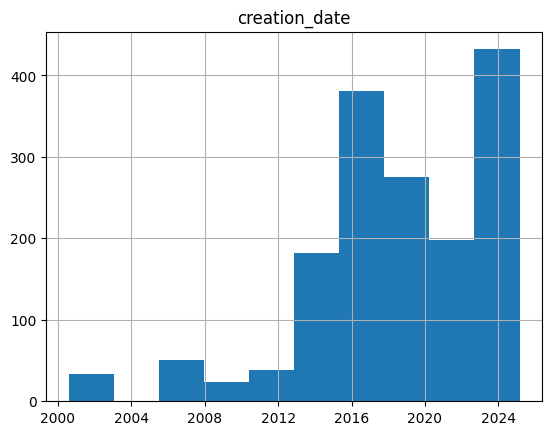

In [94]:
from datetime import datetime
filtered_df['creation_date'] = filtered_df['creation_date'].apply(lambda x: datetime.strptime(x, "%d-%b-%Y"))
filtered_df.hist('creation_date')

array([[<Axes: title={'center': 'trimed_seq_len'}>]], dtype=object)

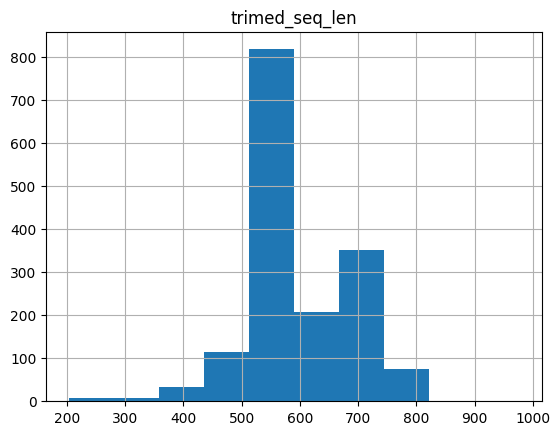

In [95]:
filtered_df.hist('trimed_seq_len')

In [96]:
def sanitize_org_name(org_name: str) -> str:
    org_name_arr = org_name.split(' ')
    to_remove = ['x', 'var.', 'var', 'aff.', 'aff', 'cf.', 'cf']
    for s in to_remove:
        try:
            org_name_arr.remove(s)
        except ValueError:
            pass
    return ' '.join(org_name_arr[:2])


In [97]:
# filtered_df['tax_id_sanitized'] = filtered_df['tax_id']
# filtered_df['organism_name_sanitized'] = filtered_df['organism_name'].apply(sanitize_org_name)
# def fix_tax_id(row: pd.Series):
#     if row['organism_name_sanitized'] == row['organism_name']:
#         return row['tax_id']
#     if row['organism_name_sanitized'] in filtered_df['organism_name'].unique():
#         new_tax_id = filtered_df.loc[filtered_df['organism_name'] == row['organism_name_sanitized']]['tax_id'].iloc[0]
#         return new_tax_id
#     return row['tax_id']

# filtered_df['tax_id_sanitized'] = filtered_df.apply(fix_tax_id, axis=1)
# sane_species = filtered_df[filtered_df['organism_name'].str.count(' ') == 1]
# dup_species = filtered_df[filtered_df['organism_name'].str.count(' ') > 1]
# dup_species.to_csv('dup-species.csv')
# filtered_df.value_counts('tax_id_sanitized')

In [98]:
tax_db = pd.read_csv('data/tax-filtered.csv', sep='\t')
seq_and_tax = filtered_df.merge(tax_db, right_on='tax_id', left_on='tax_id_sanitized', how='inner')
# remove sequences with unknown taxonomy info
#seq_and_tax = seq_and_tax.dropna(subset='genus')
seq_and_tax

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,...,trimed_seq_len,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
0,FJ008025.1,2016-07-26,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,977,132615,Phytophthora gloveri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1,L04457.1,2016-07-25,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,801,4788,Phytophthora megasperma,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
2,NC_063789.1,2023-04-13,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,780,272952,Hyaloperonospora arabidopsidis,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Hyaloperonospora
3,MH325167.1,2018-12-18,"Peronospora effusa isolate R14 mitochondrion, ...","Fletcher,K., Klosterman,S.J., Derevnina,L., Ma...",ATGACAATAATAAATTATATAACTAATCAATTTACTTTTTTAGATG...,41318,Peronospora effusa,542832,9985,10762,...,777,542832,Peronospora effusa,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronospora
4,MN883605.1,2020-12-13,Phytophthora novae-guineae culture ICMP:19637 ...,"Winkworth,R.C., Nelson,B.C.W., Bellgard,S.E., ...",TTATACATTAAAATCAAAATTGATTTTATTTTTTAACCAAGTTAAA...,37072,Phytophthora novae-guineae,3070859,27456,28233,...,777,3070859,Phytophthora novae-guineae,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1603,EU595784.1,2016-07-26,Phytophthora drechsleri strain ATCC MYA-4163 c...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CAATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,256,Phytophthora drechsleri,4794,<0,>256,...,256,4794,Phytophthora drechsleri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1604,OK336442.1,2022-03-16,Peronosclerospora eriochloae voucher BRIP 1369...,"Ryley,M.J., Tan,Y.P., Kruse,J., Thines,M. and ...",TCAATGGTATTGGAGTTATGAATATTCCGATAATTTAGAATTTTCC...,251,Peronosclerospora eriochloae,1081074,<0,>251,...,251,1081074,Peronosclerospora eriochloae,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronosclerospora
1605,EU595782.1,2016-07-26,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,210,565287,Phytophthora irrigata,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1606,MF372728.1,2017-07-23,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,203,2019374,Plasmopara destructor,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara


In [99]:
seq_and_tax.to_csv('seq-and-tax-clust.csv')

### Construct SINTAX compatible db

In [100]:
from Bio.Seq import Seq
with open('data/cox2-db-clust.fa', 'w') as out:
    for index, row in seq_and_tax.iterrows():
        print(f'>{row["accession"]};tax=d:{row["domain"]};k:{row["kingdom"]};p:{row["phylum"]};c:{row["class"]};o:{row["order"]};f:{row["family"]};g:{row["genus"]};s:{row["organism_name_sanitized"].replace(" ", "+")}', file=out)
        if int(row['cox2_strand']) == -1:
            seq = Seq(row['sequence'])
            print(seq.reverse_complement(), file=out)
        else:
            print(row['sequence'], file=out)

In [101]:
seq_and_tax['sequence_trimmed_len'] = seq_and_tax['sequence'].apply(len)
seq_and_tax

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,...,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus,sequence_trimmed_len
0,FJ008025.1,2016-07-26,Phytophthora glovera isolate 11099 cytochrome ...,"Abad,Z.G., Ivors,K.L., Gallup,C.A., Abad,J.A. ...",ATGGAAGGTATTATAAATTTTCATCATGATTTAATGTTTTTTTTAA...,977,Phytophthora gloveri,132615,0,977,...,132615,Phytophthora gloveri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,977
1,L04457.1,2016-07-25,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,4788,Phytophthora megasperma,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,801
2,NC_063789.1,2023-04-13,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,272952,Hyaloperonospora arabidopsidis,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Hyaloperonospora,780
3,MH325167.1,2018-12-18,"Peronospora effusa isolate R14 mitochondrion, ...","Fletcher,K., Klosterman,S.J., Derevnina,L., Ma...",ATGACAATAATAAATTATATAACTAATCAATTTACTTTTTTAGATG...,41318,Peronospora effusa,542832,9985,10762,...,542832,Peronospora effusa,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronospora,777
4,MN883605.1,2020-12-13,Phytophthora novae-guineae culture ICMP:19637 ...,"Winkworth,R.C., Nelson,B.C.W., Bellgard,S.E., ...",TTATACATTAAAATCAAAATTGATTTTATTTTTTAACCAAGTTAAA...,37072,Phytophthora novae-guineae,3070859,27456,28233,...,3070859,Phytophthora novae-guineae,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1603,EU595784.1,2016-07-26,Phytophthora drechsleri strain ATCC MYA-4163 c...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CAATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,256,Phytophthora drechsleri,4794,<0,>256,...,4794,Phytophthora drechsleri,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,256
1604,OK336442.1,2022-03-16,Peronosclerospora eriochloae voucher BRIP 1369...,"Ryley,M.J., Tan,Y.P., Kruse,J., Thines,M. and ...",TCAATGGTATTGGAGTTATGAATATTCCGATAATTTAGAATTTTCC...,251,Peronosclerospora eriochloae,1081074,<0,>251,...,1081074,Peronosclerospora eriochloae,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronosclerospora,251
1605,EU595782.1,2016-07-26,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,565287,Phytophthora irrigata,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora,210
1606,MF372728.1,2017-07-23,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,2019374,Plasmopara destructor,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara,203
